In [1]:
# ============================================================
# TASK 4 — STAGE 1: DATASET LOADING
# ============================================================

import pandas as pd
import os

DATA_PATH = "/kaggle/input/datasets/abdulsami324243/wholesale-customers-data-set/Wholesale customers data.csv"

# Safety: verify the file exists; if not, search for it
if not os.path.exists(DATA_PATH):
    print("Path not found. Searching /kaggle/input for Wholesale customers data.csv ...")
    for root, dirs, files in os.walk("/kaggle/input"):
        for f in files:
            if "wholesale" in f.lower() and f.lower().endswith(".csv"):
                DATA_PATH = os.path.join(root, f)
                print("Found at:", DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Shape: (440, 8)
Columns: ['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185


In [2]:
# ============================================================
# TASK 4 — STAGE 3: PREPROCESSING
# ============================================================

from sklearn.preprocessing import StandardScaler

# Use the six product-spending columns ONLY.
# Do NOT include 'Channel' or 'Region' — those are labels, not features.
feature_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]

print("Missing values in features:", df[feature_cols].isna().sum().sum())

X_scaled = StandardScaler().fit_transform(df[feature_cols].values)
print("Scaled shape:", X_scaled.shape)

Missing values in features: 0
Scaled shape: (440, 6)


In [3]:
# ============================================================
# TASK 4 — STAGE 4: TRAINING
# ============================================================

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)

print("Cluster centers (scaled space):")
print(kmeans.cluster_centers_)

Cluster centers (scaled space):
[[-1.23436296e-01  1.84348655e+00  2.18120855e+00 -1.81822945e-01
   2.19348095e+00  3.01512198e-01]
 [ 4.95654341e-03 -2.28048013e-01 -2.54553236e-01 -2.70676053e-02
  -2.48890139e-01 -8.01434183e-02]
 [ 1.80335587e+00  3.33298726e+00  9.42518505e-01  9.40980070e+00
  -4.46409015e-01  8.96415723e+00]]


In [4]:
# ============================================================
# TASK 4 — STAGE 5: TESTING
# ============================================================

df["Cluster"] = kmeans.predict(X_scaled)

print("Cluster sizes:")
print(df["Cluster"].value_counts().sort_index())

Cluster sizes:
Cluster
0     45
1    393
2      2
Name: count, dtype: int64


In [5]:
# ============================================================
# TASK 4 — STAGE 6: VALIDATION
# ============================================================

# Compare clusters to the true Channel label (1 = Hotel/Restaurant, 2 = Retail)
comparison = pd.crosstab(df["Cluster"], df["Channel"])
print(comparison)

# Also look at per-cluster mean spending to interpret each segment
print("\nPer-cluster feature means:")
print(df.groupby("Cluster")[feature_cols].mean().round(1))

Channel    1   2
Cluster         
0          1  44
1        295  98
2          2   0

Per-cluster feature means:
           Fresh     Milk  Grocery   Frozen  Detergents_Paper  Delicassen
Cluster                                                                  
0        10440.9  19386.4  28656.1   2190.2           13327.8      2374.2
1        12062.9   4115.1   5535.0   2940.7            1696.2      1299.1
2        34782.0  30367.0  16898.0  48701.5             755.5     26776.0


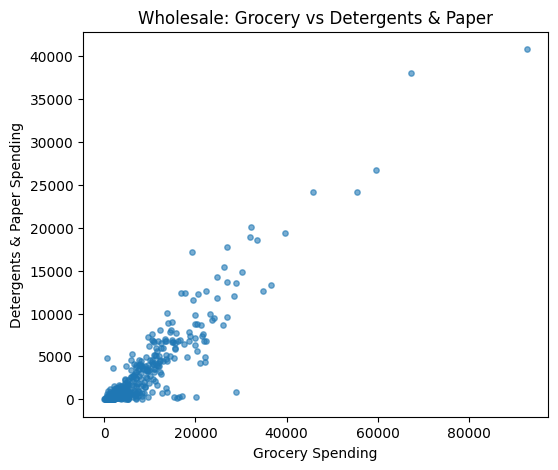

In [6]:
# ============================================================
# TASK 4 — STAGE 2: VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.scatter(df["Grocery"], df["Detergents_Paper"], s=15, alpha=0.6)
plt.xlabel("Grocery Spending")
plt.ylabel("Detergents & Paper Spending")
plt.title("Wholesale: Grocery vs Detergents & Paper")
plt.show()